# Predicting Human Plasma Protein Binding (Fub) with Machine Learning

**Paper:** Ingle et al. (2016), *Informing the Human Plasma Protein Binding of Environmental Chemicals by Machine Learning in the Pharmaceutical Space: Applicability Domain and Limits of Predictability*.  
**Journal:** *Journal of Chemical Information and Modeling*, 56, 2243–2252.  
**DOI:** [10.1021/acs.jcim.6b00291](https://doi.org/10.1021/acs.jcim.6b00291)

## Project objective

Build quantitative structure–activity relationship (QSAR) regression models that predict the fraction of a chemical that remains unbound in human plasma, **Fub**, using molecular descriptors.

The central experiment is a transfer-learning-style evaluation: train only on pharmaceuticals, then test on held-out pharmaceuticals and environmental chemicals from ToxCast. No ToxCast compound is used to train the models.

**Important:** This notebook uses the `Set` labels in the supplied spreadsheet (`Dtr`, `Dte`, `T1`, `T2`) to reproduce the paper's partitions. It does not randomly split the pharmaceutical rows again.

## 1. Understand the problem

Plasma proteins such as human serum albumin (HSA) and alpha-1-acid glycoprotein (AAG) bind chemicals in blood. The unbound fraction, Fub, is important because the unbound chemical is generally more available to cross membranes, interact with biological targets, and undergo metabolism.

Experimental Fub measurements are scarce for many environmental chemicals. The paper investigates whether a model trained on pharmaceutical measurements can predict Fub for environmental chemicals.

### Problem statement

Given a chemical's molecular descriptors, predict its experimental Fub value, a continuous value between 0 and 1.

### Research questions

1. Can models trained only on pharmaceuticals predict Fub for unseen environmental chemicals?
2. How do k-nearest neighbors (kNN), support vector regression (SVR), and random forest (RF) compare?
3. Does averaging the three models into a consensus prediction improve performance?
4. Does prediction error depend on binding strength or ionization class?
5. Can simple applicability-domain checks identify unreliable predictions?

### Workflow

1. Load and inspect the curated spreadsheet.
2. Identify the four preassigned data partitions.
3. Transform Fub to the paper's scaled logit-like target, ln Ka.
4. Select descriptors using repeated random-forest feature-importance rankings.
5. Train kNN, SVR, and RF using pharmaceutical training compounds only.
6. Evaluate with five-fold cross-validation and the three independent test sets.
7. Compare results with Table 1 in the paper.
8. Examine errors by binding strength and, if the supplied file contains it, ionization class.
9. Assess applicability domain using descriptor ranges and PCA.
10. Optionally compare a gradient-boosting model as an extension.

## 2. Dataset and expected columns

The curated dataset is `PPB_JChemInfMod_Supp_AllData.xlsx`. The paper describes 1,245 pharmaceuticals and 406 ToxCast chemicals. The spreadsheet's `Set` column identifies the partitions:

| Spreadsheet label | Meaning | Expected count | Role |
|---|---|---:|---|
| `Dtr` | Pharmaceutical training | 1,045 | Train |
| `Dte` | Pharmaceutical test | 200 | In-domain test |
| `T1` | ToxCast I | 238 | Environmental test |
| `T2` | ToxCast II | 168 | Blind environmental test |

The paper reports that the experimental data were curated before modelling: repeated measurements were averaged, highly conflicting pharmaceutical records were removed, and compounds found in both pharmaceutical and ToxCast sources were assigned to the pharmaceutical set. **Do not repeat that curation here.**

### Descriptor columns supplied for this notebook

The feature list below is based on the column names you provided. It contains 22 candidate numeric descriptor columns. The notebook checks which are actually present and numeric. Identifier, structure/name fields, target, set label, and stored author prediction columns are never used as model inputs.

> The column list you supplied does not show an explicit `Ionization` column. The ionization analysis is therefore conditional: it runs only if an ionization-class column is actually present. The notebook will not guess ionization classes from descriptor names.

## 3. Import libraries and set reproducibility options

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)


## 4. Load the spreadsheet

In [2]:
# Keep the Excel file in the same folder as this notebook,
# or replace the path below with the full path to your file.
DATA_PATH = Path("PPB_JChemInfMod_Supp_AllData.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place the Excel file beside this notebook "
        "or update DATA_PATH."
    )

df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
for column in df.columns:
    print(" -", repr(column))

print("\nFirst five rows:")
display(df.head())


Dataset shape: (1651, 32)

Column names:
 - 'ID#'
 - 'Set'
 - 'SMILES'
 - 'Fub'
 - 'Name'
 - 'CAS'
 - 'a_base'
 - 'a_nN'
 - 'a_nS'
 - 'BCUT_SLOGP_0'
 - 'BCUT_SLOGP_2'
 - 'GCUT_PEOE_0'
 - 'GCUT_PEOE_1'
 - 'GCUT_SLOGP_0'
 - 'GCUT_SMR_0'
 - 'logP(o/w)'
 - 'logS'
 - 'PEOE_VSA+1'
 - 'PEOE_VSA+4'
 - 'PEOE_VSA_FPOL'
 - 'PEOE_VSA_FPPOS'
 - 'PEOE_VSA_POL'
 - 'PEOE_VSA_PPOS'
 - 'SlogP'
 - 'SlogP_VSA6'
 - 'SMR_VSA6'
 - 'VAdjEq'
 - 'ABNW'
 - 'kNN_Pred'
 - 'SVM_Pred'
 - 'RF_Pred'
 - 'Con_Pred'

First five rows:


,ID#,Set,SMILES,Fub,Name,CAS,a_base,a_nN,a_nS,BCUT_SLOGP_0,BCUT_SLOGP_2,GCUT_PEOE_0,GCUT_PEOE_1,GCUT_SLOGP_0,GCUT_SMR_0,logP(o/w),logS,PEOE_VSA+1,PEOE_VSA+4,PEOE_VSA_FPOL,PEOE_VSA_FPPOS,PEOE_VSA_POL,PEOE_VSA_PPOS,SlogP,SlogP_VSA6,SMR_VSA6,VAdjEq,ABNW,kNN_Pred,SVM_Pred,RF_Pred,Con_Pred
0,1.0004,Dte,OC1(CCC2C3C(CCC12C)C1(C(=CC(=O)CC1)CC3)C)C(=O)C,0.15,17-hydroxyprogesterone,NaN,0,0,0,-2.870618,0.397666,-0.794701,-0.367739,-0.923300,-0.539023,2.84900,-4.80278,45.216946,0.000000,0.137061,0.000000,40.700764,0.000000,3.83840,0.000000,11.375222,0.448864,Ni,0.065,0.066,0.137,0.089333
1,1.0005,Dte,OC1CCC2C3C(CCC12C)c1c(cc(O)cc1)CC3,0.02,17-a-estradiol,NaN,0,0,0,-2.803789,0.603392,-0.803359,-0.397914,-0.883601,-0.535662,3.85100,-4.21839,0.000000,0.000000,0.059825,0.000000,13.566921,0.000000,3.60917,4.410796,0.000000,0.514816,Ni,0.049,0.049,0.036,0.044667
2,1.0012,Dte,Fc1cc2c(N(C=C(C(O)=O)C2=O)c2cc(ccc2)C(F)(F)F)c...,0.38,3b(m-CF3),NaN,0,3,0,-2.888218,0.704054,-0.843703,-0.457774,-1.154434,-0.503589,3.00976,-5.06262,72.015152,8.458519,0.214715,0.089898,76.937576,32.212521,3.86850,7.759516,87.191391,0.368752,Zi,0.605,0.053,0.331,0.329667
3,1.0019,Dte,Fc1cc2c(N(C=C(C(O)=O)C2=O)c2cc(OC)ccc2)cc1N1CC...,0.65,5b(m-OCH3),NaN,0,3,0,-2.888218,0.681423,-0.843702,-0.465880,-1.154434,-0.503591,2.03100,-4.05645,78.265129,8.458519,0.196656,0.064719,70.395828,23.167019,2.54680,0.000000,87.191391,0.388286,Zi,0.615,0.234,0.662,0.503667
4,1.0026,Dte,Fc1cc2c(N(C=C(C(O)=O)C2=O)c2ccc([N+](=O)[O-])c...,0.70,7c(p-NO2),NaN,0,4,0,-2.888218,0.764078,-0.843702,-0.458581,-1.154434,-0.503591,1.97300,-4.79630,105.451630,8.458519,0.304837,0.083894,108.522670,29.866570,2.44640,0.000000,87.191391,0.378242,Zi,0.615,0.214,0.404,0.411000


In [3]:
# Check missing values and data types before modelling.
missing_summary = df.isna().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

print("Missing values by column:")
display(missing_summary.to_frame("missing_count"))

print("\nData types:")
display(df.dtypes.to_frame("dtype"))


Missing values by column:


,missing_count
CAS,710



Data types:


,dtype
ID#,float64
Set,object
SMILES,object
Fub,float64
Name,object
CAS,object
a_base,int64
a_nN,int64
a_nS,int64
BCUT_SLOGP_0,float64


In [4]:
# Summary statistics help verify the target and descriptor ranges.
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID#,1651.0,NaN,NaN,NaN,2.666695,1.516841,1.0001,1.04135,3.0094,4.02685,5.0168
Set,1651,4,Dtr,1045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SMILES,1651,1629,FC(F)(F)c1cc(NC(=O)C(C)C)ccc1[N+](=O)[O-],2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fub,1651.0,NaN,NaN,NaN,0.307814,0.329158,0.0,0.03,0.15,0.56,1.0
Name,1651,1649,Erythromycin,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAS,941,934,30516-87-1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
a_base,1651.0,NaN,NaN,NaN,0.024228,0.182625,0.0,0.0,0.0,0.0,2.0
a_nN,1651.0,NaN,NaN,NaN,2.239249,2.11524,0.0,1.0,2.0,3.0,18.0
a_nS,1651.0,NaN,NaN,NaN,0.346457,0.647525,0.0,0.0,0.0,1.0,6.0
BCUT_SLOGP_0,1651.0,NaN,NaN,NaN,-2.662895,0.232563,-3.103366,-2.857784,-2.706392,-2.533649,-1.851802


## 5. Configure target, split labels, and descriptors

The experimental target is `Fub`. Do not use the spreadsheet's stored `kNN_Pred`, `SVM_Pred`, `RF_Pred`, or `Con_Pred` columns as features: those are existing model outputs and would cause target leakage.

The `Set` mapping below follows the labels observed in your spreadsheet:
- `Dtr` → pharmaceutical training
- `Dte` → pharmaceutical test
- `T1` → ToxCast I
- `T2` → ToxCast II

In [5]:
TARGET = "Fub"
SET_COLUMN = "Set"

GROUP_MAPPING = {
    "Dtr": "pharma_train",
    "Dte": "drug_test",
    "T1": "toxcast1",
    "T2": "toxcast2",
}

# Candidate descriptors from the column list you supplied.
DESCRIPTOR_CANDIDATES = [
    "a_base",
    "a_nN",
    "a_nS",
    "BCUT_SLOGP_0",
    "BCUT_SLOGP_2",
    "GCUT_PEOE_0",
    "GCUT_PEOE_1",
    "GCUT_SLOGP_0",
    "GCUT_SMR_0",
    "logP(o/w)",
    "logS",
    "PEOE_VSA+1",
    "PEOE_VSA+4",
    "PEOE_VSA_FPOL",
    "PEOE_VSA_FPPOS",
    "PEOE_VSA_POL",
    "PEOE_VSA_PPOS",
    "SlogP",
    "SlogP_VSA6",
    "SMR_VSA6",
    "VAdjEq",
    "ABNW",
]

# Stored predictions and identifiers are explicitly excluded.
EXCLUDED_COLUMNS = {
    "ID#", "Set", "SMILES", "Fub", "Name", "CAS",
    "kNN_Pred", "SVM_Pred", "RF_Pred", "Con_Pred",
}

required_columns = [TARGET, SET_COLUMN]
missing_required = [column for column in required_columns if column not in df.columns]

if missing_required:
    raise KeyError(f"Required columns are missing: {missing_required}")

descriptor_columns = [
    column for column in DESCRIPTOR_CANDIDATES
    if column in df.columns and column not in EXCLUDED_COLUMNS
]

missing_descriptors = [
    column for column in DESCRIPTOR_CANDIDATES
    if column not in df.columns
]

if not descriptor_columns:
    raise ValueError("No descriptor columns from DESCRIPTOR_CANDIDATES were found.")

print(f"Descriptor columns found: {len(descriptor_columns)}")
print(descriptor_columns)

if missing_descriptors:
    print("\nCandidate descriptors not found in this spreadsheet:")
    print(missing_descriptors)


Descriptor columns found: 22
['a_base', 'a_nN', 'a_nS', 'BCUT_SLOGP_0', 'BCUT_SLOGP_2', 'GCUT_PEOE_0', 'GCUT_PEOE_1', 'GCUT_SLOGP_0', 'GCUT_SMR_0', 'logP(o/w)', 'logS', 'PEOE_VSA+1', 'PEOE_VSA+4', 'PEOE_VSA_FPOL', 'PEOE_VSA_FPPOS', 'PEOE_VSA_POL', 'PEOE_VSA_PPOS', 'SlogP', 'SlogP_VSA6', 'SMR_VSA6', 'VAdjEq', 'ABNW']


In [6]:
# Convert the selected descriptors and target to numeric values.
# Invalid text entries become NaN and will be imputed using training data only.
for column in descriptor_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

# Standardise the Set labels and map them to readable group names.
df[SET_COLUMN] = df[SET_COLUMN].astype(str).str.strip()
df["group"] = df[SET_COLUMN].map(GROUP_MAPPING)

unknown_labels = sorted(df.loc[df["group"].isna(), SET_COLUMN].unique())

if unknown_labels:
    raise ValueError(
        "Unrecognised values in the Set column: "
        f"{unknown_labels}. Update GROUP_MAPPING before continuing."
    )

print("Original partition counts:")
display(df[SET_COLUMN].value_counts().rename_axis("Set").to_frame("count"))

print("\nMapped partition counts:")
display(df["group"].value_counts().rename_axis("group").to_frame("count"))


Original partition counts:


,count
Set,
Dtr,1045
T1,238
Dte,200
T2,168



Mapped partition counts:


,count
group,
pharma_train,1045
toxcast1,238
drug_test,200
toxcast2,168


In [7]:
# The expected counts come from the paper and the supplied dataset description.
EXPECTED_COUNTS = {
    "pharma_train": 1045,
    "drug_test": 200,
    "toxcast1": 238,
    "toxcast2": 168,
}

observed_counts = df["group"].value_counts().to_dict()

for group_name, expected_count in EXPECTED_COUNTS.items():
    observed_count = observed_counts.get(group_name, 0)
    status = "OK" if observed_count == expected_count else "CHECK"
    print(f"{group_name:15s}: {observed_count:4d} rows (expected {expected_count}) [{status}]")

print("\nFub range:")
print(df[TARGET].describe())

if not df[TARGET].dropna().between(0, 1).all():
    raise ValueError("Fub contains values outside [0, 1]. Inspect the target values.")


pharma_train   : 1045 rows (expected 1045) [OK]
drug_test      :  200 rows (expected 200) [OK]
toxcast1       :  238 rows (expected 238) [OK]
toxcast2       :  168 rows (expected 168) [OK]

Fub range:
count    1651.000000
mean        0.307814
std         0.329158
min         0.000000
25%         0.030000
50%         0.150000
75%         0.560000
max         1.000000
Name: Fub, dtype: float64


## 6. Transform the target: Fub to ln Ka

The paper models a transformed target rather than raw Fub:

\[
\ln K_a = 0.3\ln\left(\frac{1-F_{ub}}{F_{ub}}\right)
\]

After prediction, convert ln Ka back to Fub:

\[
F_{ub} = \frac{1}{1+\exp(\ln K_a/0.3)}
\]

The clipping step is essential because values at exactly 0 or 1 would otherwise produce infinite logarithms. Predictions are evaluated only after conversion back to the Fub scale.

In [8]:
def fub_to_lnka(fub):
    """Convert Fub to the paper's scaled ln Ka target, clipping edge values."""
    fub = np.asarray(fub, dtype=float)
    fub = np.clip(fub, 1e-3, 1 - 1e-3)
    return 0.3 * np.log((1 - fub) / fub)


def lnka_to_fub(lnka):
    """Convert predicted ln Ka values back to Fub."""
    lnka = np.asarray(lnka, dtype=float)
    return 1.0 / (1.0 + np.exp(np.clip(lnka / 0.3, -700, 700)))


# Check the forward and inverse transformations, including Fub = 1.
example_fub = np.array([0.001, 0.05, 0.5, 0.95, 1.0])
round_trip = lnka_to_fub(fub_to_lnka(example_fub))

print("Original Fub: ", example_fub)
print("Round trip:  ", np.round(round_trip, 4))


Original Fub:  [0.001 0.05  0.5   0.95  1.   ]
Round trip:   [0.001 0.05  0.5   0.95  0.999]


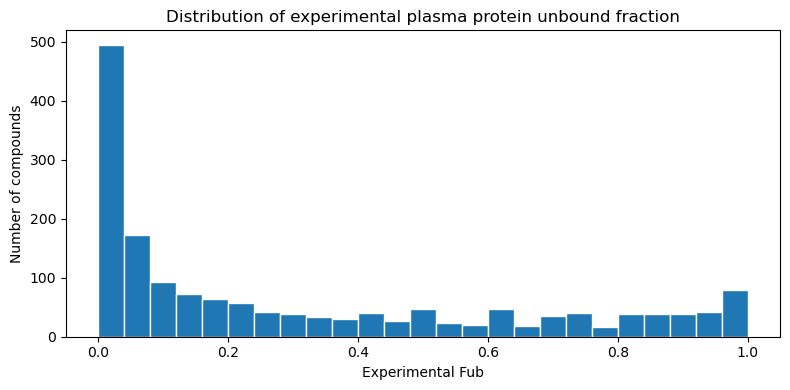

Fraction with Fub < 0.15: 0.487
Fraction with Fub > 0.85: 0.119


In [9]:
# Visualise the target distribution before modelling.
plt.figure(figsize=(8, 4))
plt.hist(df[TARGET].dropna(), bins=25, edgecolor="white")
plt.xlabel("Experimental Fub")
plt.ylabel("Number of compounds")
plt.title("Distribution of experimental plasma protein unbound fraction")
plt.tight_layout()
plt.show()

print("Fraction with Fub < 0.15:", round((df[TARGET] < 0.15).mean(), 3))
print("Fraction with Fub > 0.85:", round((df[TARGET] > 0.85).mean(), 3))


## 7. Create the four data partitions

Use the supplied `Set` labels directly. The paper uses 1,045 pharmaceutical compounds for training, 200 held-out pharmaceuticals for in-domain testing, and two independent ToxCast sets for environmental testing.

Only rows with a missing target are excluded. Missing descriptor values are **not** used as a reason to discard a compound; they are imputed later using statistics learned from the training partition.

In [16]:
# Keep compounds with a measured Fub value.
data = df.dropna(subset=[TARGET]).copy()
data[TARGET] = data[TARGET].clip(0, 1)

train_df = data[data["group"] == "pharma_train"].copy()
drug_test = data[data["group"] == "drug_test"].copy()
tox1 = data[data["group"] == "toxcast1"].copy()
tox2 = data[data["group"] == "toxcast2"].copy()

print("Pharmaceutical training:", len(train_df))
print("Pharmaceutical test:    ", len(drug_test))
print("ToxCast I:              ", len(tox1))
print("ToxCast II:             ", len(tox2))

if len(train_df) < 2:
    raise ValueError("The pharmaceutical training partition is empty or too small.")

if len(drug_test) == 0 or len(tox1) == 0 or len(tox2) == 0:
    raise ValueError("One or more test partitions are empty. Check the Set mapping.")


Pharmaceutical training: 1045
Pharmaceutical test:     200
ToxCast I:               238
ToxCast II:              168


In [17]:
# Remove descriptors that are entirely missing in training data
all_missing_train_features = [
    col for col in descriptor_columns
    if train_df[col].isna().all()
]

print("All-missing features:", all_missing_train_features)

descriptor_columns = [
    col for col in descriptor_columns
    if col not in all_missing_train_features
]

print("Remaining descriptors:", len(descriptor_columns))
print(descriptor_columns)

All-missing features: []
Remaining descriptors: 21
['a_base', 'a_nN', 'a_nS', 'BCUT_SLOGP_0', 'BCUT_SLOGP_2', 'GCUT_PEOE_0', 'GCUT_PEOE_1', 'GCUT_SLOGP_0', 'GCUT_SMR_0', 'logP(o/w)', 'logS', 'PEOE_VSA+1', 'PEOE_VSA+4', 'PEOE_VSA_FPOL', 'PEOE_VSA_FPPOS', 'PEOE_VSA_POL', 'PEOE_VSA_PPOS', 'SlogP', 'SlogP_VSA6', 'SMR_VSA6', 'VAdjEq']


In [18]:
# Inspect missing descriptor values in each partition.
missing_by_partition = pd.DataFrame({
    "train": train_df[descriptor_columns].isna().sum(),
    "drug_test": drug_test[descriptor_columns].isna().sum(),
    "toxcast1": tox1[descriptor_columns].isna().sum(),
    "toxcast2": tox2[descriptor_columns].isna().sum(),
})

display(missing_by_partition)


,train,drug_test,toxcast1,toxcast2
a_base,0,0,0,0
a_nN,0,0,0,0
a_nS,0,0,0,0
BCUT_SLOGP_0,0,0,0,0
BCUT_SLOGP_2,0,0,0,0
GCUT_PEOE_0,0,0,0,0
GCUT_PEOE_1,0,0,0,0
GCUT_SLOGP_0,0,0,0,0
GCUT_SMR_0,0,0,0,0
logP(o/w),0,0,0,0


## 8. Descriptor selection using repeated Random Forest rankings

The paper ranks descriptors using Random Forest node-purity / feature-importance scores. It repeatedly fits a Random Forest on a randomly selected half of the pharmaceutical training data, records the top 15 descriptors, and retains the descriptors that recur most often.

This notebook follows that stability-selection idea:
- 10 repeated half-sample fits;
- 500 trees per Random Forest;
- top 15 descriptors recorded per repeat;
- kNN uses 15 selected descriptors;
- SVR and RF use the first 10 in the recurring ranking.

The same selected ranking is used for the final model fits. During cross-validation, selection is repeated using only each fold's training portion to avoid selecting features using that fold's validation rows.

In [19]:
def select_features_by_recurrence(
    training_frame,
    feature_names,
    n_repeats=10,
    top_per_repeat=15,
    random_seed=SEED,
):
    """Rank descriptors by how often they appear among repeated RF top features."""
    X = training_frame[feature_names].copy()
    y = fub_to_lnka(training_frame[TARGET].values)

    votes = Counter()

    for repeat in range(n_repeats):
        rng = np.random.RandomState(random_seed + repeat)
        sample_size = max(2, int(np.ceil(len(X) * 0.5)))
        sampled_positions = rng.choice(
            len(X),
            size=sample_size,
            replace=False,
        )

        X_sample = X.iloc[sampled_positions]

        # Fit imputation on this half-sample only.
        imputer = SimpleImputer(strategy="median")
        X_sample_imputed = imputer.fit_transform(X_sample)

        rf_selector = RandomForestRegressor(
            n_estimators=500,
            random_state=random_seed + repeat,
            n_jobs=-1,
        )
        rf_selector.fit(X_sample_imputed, y[sampled_positions])

        top_indices = np.argsort(rf_selector.feature_importances_)[::-1]
        top_indices = top_indices[:min(top_per_repeat, len(feature_names))]
        votes.update(top_indices.tolist())

    ranked_indices = [
        index for index, count in votes.most_common()
    ]
    ranked_features = [feature_names[index] for index in ranked_indices]

    return ranked_features, votes


In [20]:
# Select the final descriptor ranking using the complete pharmaceutical training set.
selected_features, feature_votes = select_features_by_recurrence(
    train_df,
    descriptor_columns,
)

feat_knn = selected_features[:15]
feat_svm = selected_features[:10]
feat_rf = selected_features[:10]

print("Recurring descriptor ranking:")
display(pd.DataFrame({
    "descriptor": selected_features,
    "votes": [feature_votes[descriptor_columns.index(name)] for name in selected_features],
}))

print("\nkNN features:", feat_knn)
print("\nSVR features:", feat_svm)
print("\nRF features:", feat_rf)


Recurring descriptor ranking:


,descriptor,votes
0,logS,10
1,logP(o/w),10
2,SlogP,10
3,GCUT_PEOE_0,10
4,GCUT_PEOE_1,10
5,GCUT_SMR_0,10
6,BCUT_SLOGP_2,10
7,BCUT_SLOGP_0,10
8,GCUT_SLOGP_0,10
9,PEOE_VSA+1,10



kNN features: ['logS', 'logP(o/w)', 'SlogP', 'GCUT_PEOE_0', 'GCUT_PEOE_1', 'GCUT_SMR_0', 'BCUT_SLOGP_2', 'BCUT_SLOGP_0', 'GCUT_SLOGP_0', 'PEOE_VSA+1', 'PEOE_VSA_FPOL', 'SMR_VSA6', 'VAdjEq', 'PEOE_VSA_FPPOS', 'PEOE_VSA_PPOS']

SVR features: ['logS', 'logP(o/w)', 'SlogP', 'GCUT_PEOE_0', 'GCUT_PEOE_1', 'GCUT_SMR_0', 'BCUT_SLOGP_2', 'BCUT_SLOGP_0', 'GCUT_SLOGP_0', 'PEOE_VSA+1']

RF features: ['logS', 'logP(o/w)', 'SlogP', 'GCUT_PEOE_0', 'GCUT_PEOE_1', 'GCUT_SMR_0', 'BCUT_SLOGP_2', 'BCUT_SLOGP_0', 'GCUT_SLOGP_0', 'PEOE_VSA+1']


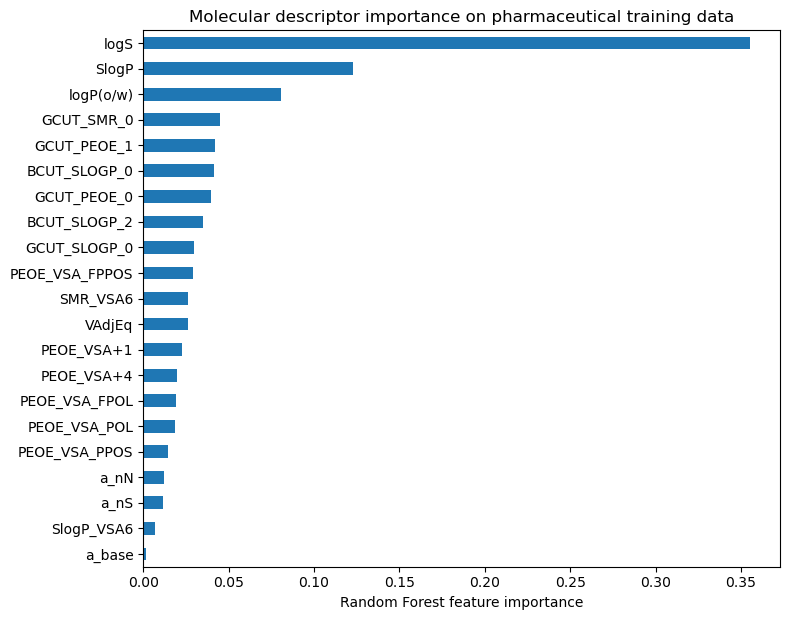

,importance
logS,0.355008
SlogP,0.122596
logP(o/w),0.080881
GCUT_SMR_0,0.044954
GCUT_PEOE_1,0.041728
BCUT_SLOGP_0,0.041576
GCUT_PEOE_0,0.039394
BCUT_SLOGP_2,0.035001
GCUT_SLOGP_0,0.029637
PEOE_VSA_FPPOS,0.029391


In [21]:
# Fit a final RF importance model on all training compounds for a simple importance plot.
X_train_for_importance = train_df[descriptor_columns]
importance_imputer = SimpleImputer(strategy="median")
X_train_imputed = importance_imputer.fit_transform(X_train_for_importance)

importance_rf = RandomForestRegressor(
    n_estimators=500,
    random_state=SEED,
    n_jobs=-1,
)
importance_rf.fit(X_train_imputed, fub_to_lnka(train_df[TARGET].values))

importance = pd.Series(
    importance_rf.feature_importances_,
    index=descriptor_columns,
).sort_values()

plt.figure(figsize=(8, max(4, 0.3 * len(importance))))
importance.plot(kind="barh")
plt.xlabel("Random Forest feature importance")
plt.title("Molecular descriptor importance on pharmaceutical training data")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))


## 9. Train kNN, SVR, and Random Forest; create consensus predictions

Paper hyperparameters:

- **kNN:** `n_neighbors=10`
- **SVR:** RBF kernel, `epsilon=0.3162`, `C=50`
- **Random Forest:** 500 trees

kNN and SVR use standardised descriptors. The imputer and scaler are fitted on the relevant training rows only. Random Forest does not require scaling.

The consensus prediction is the arithmetic mean of the three model predictions **after each prediction has been converted back to Fub**.

In [22]:
def fit_predict_models(training_frame, prediction_frame, feature_sets):
    """Fit the three paper models and return predictions on the Fub scale."""
    y_train = fub_to_lnka(training_frame[TARGET].values)
    output = pd.DataFrame(index=prediction_frame.index)

    # kNN: median imputation followed by standardisation.
    knn_features = feature_sets["kNN"]
    knn_imputer = SimpleImputer(strategy="median")
    X_knn_train = knn_imputer.fit_transform(training_frame[knn_features])
    X_knn_test = knn_imputer.transform(prediction_frame[knn_features])

    knn_scaler = StandardScaler()
    X_knn_train = knn_scaler.fit_transform(X_knn_train)
    X_knn_test = knn_scaler.transform(X_knn_test)

    knn_model = KNeighborsRegressor(n_neighbors=10)
    knn_model.fit(X_knn_train, y_train)
    output["kNN"] = lnka_to_fub(knn_model.predict(X_knn_test))

    # SVR: median imputation followed by standardisation.
    svm_features = feature_sets["SVM"]
    svm_imputer = SimpleImputer(strategy="median")
    X_svm_train = svm_imputer.fit_transform(training_frame[svm_features])
    X_svm_test = svm_imputer.transform(prediction_frame[svm_features])

    svm_scaler = StandardScaler()
    X_svm_train = svm_scaler.fit_transform(X_svm_train)
    X_svm_test = svm_scaler.transform(X_svm_test)

    svm_model = SVR(
        kernel="rbf",
        epsilon=0.3162,
        C=50,
    )
    svm_model.fit(X_svm_train, y_train)
    output["SVM"] = lnka_to_fub(svm_model.predict(X_svm_test))

    # Random Forest: imputation is required if descriptor values are missing,
    # but feature scaling is not required.
    rf_features = feature_sets["RF"]
    rf_imputer = SimpleImputer(strategy="median")
    X_rf_train = rf_imputer.fit_transform(training_frame[rf_features])
    X_rf_test = rf_imputer.transform(prediction_frame[rf_features])

    rf_model = RandomForestRegressor(
        n_estimators=500,
        random_state=SEED,
        n_jobs=-1,
    )
    rf_model.fit(X_rf_train, y_train)
    output["RF"] = lnka_to_fub(rf_model.predict(X_rf_test))

    # Average in Fub space, not in transformed ln Ka space.
    output["consensus"] = output[["kNN", "SVM", "RF"]].mean(axis=1)
    output["actual"] = prediction_frame[TARGET].values

    return output


## 10. Five-fold cross-validation on the pharmaceutical training set

The paper reports training-set performance using five-fold cross-validation. Each fold's validation compounds are kept out of feature selection, imputation, scaling, and model fitting for that fold.

ToxCast data and the held-out pharmaceutical test set are not used in this cross-validation.

In [23]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

cv_predictions = []

for fold_number, (train_positions, valid_positions) in enumerate(
    kf.split(train_df),
    start=1,
):
    fold_train = train_df.iloc[train_positions].copy()
    fold_valid = train_df.iloc[valid_positions].copy()

    # Re-run descriptor selection using only this fold's training compounds.
    fold_ranking, _ = select_features_by_recurrence(
        fold_train,
        descriptor_columns,
        random_seed=SEED + fold_number * 100,
    )

    fold_feature_sets = {
        "kNN": fold_ranking[:15],
        "SVM": fold_ranking[:10],
        "RF": fold_ranking[:10],
    }

    fold_result = fit_predict_models(
        fold_train,
        fold_valid,
        fold_feature_sets,
    )

    fold_result["fold"] = fold_number
    cv_predictions.append(fold_result)

    print(
        f"Completed fold {fold_number}/5 "
        f"({len(fold_train)} training, {len(fold_valid)} validation compounds)"
    )

cv_pred = pd.concat(cv_predictions).sort_index()

print("\nCross-validation predictions:", cv_pred.shape)
display(cv_pred.head())


Completed fold 1/5 (836 training, 209 validation compounds)
Completed fold 2/5 (836 training, 209 validation compounds)
Completed fold 3/5 (836 training, 209 validation compounds)
Completed fold 4/5 (836 training, 209 validation compounds)
Completed fold 5/5 (836 training, 209 validation compounds)

Cross-validation predictions: (1045, 6)


,kNN,SVM,RF,consensus,actual,fold
200,0.518828,0.342762,0.499516,0.453702,0.40,2
201,0.150122,0.095419,0.824202,0.356581,0.65,5
202,0.146758,0.312167,0.185661,0.214862,0.38,1
203,0.105940,0.078431,0.057142,0.080505,0.02,1
204,0.642551,0.677332,0.590878,0.636921,0.69,5


## 11. Fit final models and predict the independent test sets

After cross-validation, fit the final models using all 1,045 `Dtr` compounds and the final descriptor ranking. Evaluate the models on:
- `Dte`: held-out pharmaceuticals;
- `T1`: ToxCast I;
- `T2`: ToxCast II.

ToxCast II is kept as the blind test set in the paper's design. Do not use it to choose features or tune hyperparameters.

In [24]:
final_feature_sets = {
    "kNN": feat_knn,
    "SVM": feat_svm,
    "RF": feat_rf,
}

test_sets = {
    "drug test": drug_test,
    "ToxCast I": tox1,
    "ToxCast II": tox2,
}

pred = {}

for set_name, test_frame in test_sets.items():
    pred[set_name] = fit_predict_models(
        train_df,
        test_frame,
        final_feature_sets,
    )

    print(f"Completed predictions for {set_name}: {len(test_frame)} compounds")

# Keep the five-fold CV results under the same naming convention.
pred["drug training"] = cv_pred

# Combine the three independent test sets.
pred["complete test"] = pd.concat([
    pred["drug test"],
    pred["ToxCast I"],
    pred["ToxCast II"],
]).sort_index()

display(pred["complete test"].head())


Completed predictions for drug test: 200 compounds
Completed predictions for ToxCast I: 238 compounds
Completed predictions for ToxCast II: 168 compounds


,kNN,SVM,RF,consensus,actual
0,0.082084,0.092153,0.120891,0.098376,0.15
1,0.059077,0.034127,0.027629,0.040278,0.02
2,0.635111,0.367179,0.353881,0.452057,0.38
3,0.641949,0.725964,0.656985,0.674966,0.65
4,0.610070,0.486990,0.417675,0.504912,0.70


## 12. Evaluate model performance

Report all metrics on the original Fub scale:

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** penalises large errors more strongly; lower is better.
- **R²:** complementary measure of explained variance. The paper cautions that R² is not ideal for these nonlinear models and a target distribution dominated by highly bound compounds. Interpret it alongside MAE and RMSE.

In [25]:
MODEL_NAMES = ["kNN", "SVM", "RF", "consensus"]
DATASET_ORDER = [
    "drug training",
    "drug test",
    "ToxCast I",
    "ToxCast II",
    "complete test",
]

metric_rows = []

for dataset_name in DATASET_ORDER:
    result = pred[dataset_name]
    actual = result["actual"]

    for metric_name, metric_function in [
        ("MAE", mean_absolute_error),
        ("RMSE", lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred))),
        ("R2", r2_score),
    ]:
        row = {
            "dataset": dataset_name,
            "metric": metric_name,
            "n": len(result),
        }

        for model_name in MODEL_NAMES:
            row[model_name] = metric_function(
                actual,
                result[model_name],
            )

        metric_rows.append(row)

results = pd.DataFrame(metric_rows).set_index(["dataset", "metric"])
display(results.round(3))


n    kNN    SVM     RF  consensus
dataset       metric                                      
drug training MAE     1045  0.161  0.169  0.147      0.149
              RMSE    1045  0.228  0.248  0.215      0.209
              R2      1045  0.534  0.451  0.588      0.610
drug test     MAE      200  0.164  0.176  0.156      0.157
              RMSE     200  0.232  0.263  0.231      0.224
              R2       200  0.520  0.380  0.523      0.552
ToxCast I     MAE      238  0.165  0.174  0.127      0.145
              RMSE     238  0.265  0.278  0.224      0.230
              R2       238 -0.034 -0.137  0.258      0.221
ToxCast II    MAE      168  0.139  0.166  0.113      0.130
              RMSE     168  0.234  0.271  0.201      0.208
              R2       168  0.267  0.016  0.457      0.419
complete test MAE      606  0.158  0.172  0.133      0.145
              RMSE     606  0.246  0.271  0.220      0.222
              R2       606  0.341  0.198  0.470      0.462

### Compare the results with Table 1 of the paper

In [26]:
# Reference values transcribed from Table 1 of Ingle et al. (2016).
paper_table_1 = {
    ("drug training", "MAE"):  [0.116, 0.172, 0.146, 0.151],
    ("drug training", "RMSE"): [0.233, 0.237, 0.214, 0.208],
    ("drug training", "R2"):   [0.48, 0.44, 0.52, 0.55],

    ("drug test", "MAE"):      [0.164, 0.177, 0.157, 0.155],
    ("drug test", "RMSE"):     [0.242, 0.251, 0.231, 0.225],
    ("drug test", "R2"):       [0.52, 0.50, 0.59, 0.62],

    ("ToxCast I", "MAE"):      [0.146, 0.140, 0.130, 0.131],
    ("ToxCast I", "RMSE"):     [0.228, 0.209, 0.226, 0.206],
    ("ToxCast I", "R2"):       [0.25, 0.39, 0.25, 0.39],

    ("ToxCast II", "MAE"):     [0.122, 0.155, 0.103, 0.110],
    ("ToxCast II", "RMSE"):    [0.211, 0.224, 0.187, 0.181],
    ("ToxCast II", "R2"):      [0.41, 0.39, 0.53, 0.56],

    ("complete test", "MAE"):  [0.145, 0.156, 0.131, 0.133],
    ("complete test", "RMSE"): [0.228, 0.228, 0.218, 0.206],
    ("complete test", "R2"):   [0.45, 0.47, 0.51, 0.56],
}

comparison_rows = []

for (dataset_name, metric_name), reference_values in paper_table_1.items():
    for model_name, reference_value in zip(MODEL_NAMES, reference_values):
        our_value = results.loc[(dataset_name, metric_name), model_name]

        comparison_rows.append({
            "dataset": dataset_name,
            "metric": metric_name,
            "model": model_name,
            "paper": reference_value,
            "this_run": our_value,
            "difference": our_value - reference_value,
        })

paper_comparison = pd.DataFrame(comparison_rows)
display(
    paper_comparison
    .set_index(["dataset", "metric", "model"])
    .round(3)
)


paper  this_run  difference
dataset       metric model                                 
drug training MAE    kNN        0.116     0.161       0.045
                     SVM        0.172     0.169      -0.003
                     RF         0.146     0.147       0.001
                     consensus  0.151     0.149      -0.002
              RMSE   kNN        0.233     0.228      -0.005
                     SVM        0.237     0.248       0.011
                     RF         0.214     0.215       0.001
                     consensus  0.208     0.209       0.001
              R2     kNN        0.480     0.534       0.054
                     SVM        0.440     0.451       0.011
                     RF         0.520     0.588       0.068
                     consensus  0.550     0.610       0.060
drug test     MAE    kNN        0.164     0.164       0.000
                     SVM        0.177     0.176      -0.001
                     RF         0.157     0.156      -0.001
                     consensus  0.155     0.157       0.002
              RMSE   kNN        0.242     0.232      -0.010
                     SVM        0.251     0.263       0.012
                     RF         0.231     0.231      -0.000
                     consensus  0.225     0.224      -0.001
              R2     kNN        0.520     0.520      -0.000
                     SVM        0.500     0.380      -0.120
                     RF         0.590     0.523      -0.067
                     consensus  0.620     0.552      -0.068
ToxCast I     MAE    kNN        0.146     0.165       0.019
                     SVM        0.140     0.174       0.034
                     RF         0.130     0.127      -0.003
                     consensus  0.131     0.145       0.014
              RMSE   kNN        0.228     0.265       0.037
                     SVM        0.209     0.278       0.069
                     RF         0.226     0.224      -0.002
                     consensus  0.206     0.230       0.024
              R2     kNN        0.250    -0.034      -0.284
                     SVM        0.390    -0.137      -0.527
                     RF         0.250     0.258       0.008
                     consensus  0.390     0.221      -0.169
ToxCast II    MAE    kNN        0.122     0.139       0.017
                     SVM        0.155     0.166       0.011
                     RF         0.103     0.113       0.010
                     consensus  0.110     0.130       0.020
              RMSE   kNN        0.211     0.234       0.023
                     SVM        0.224     0.271       0.047
                     RF         0.187     0.201       0.014
                     consensus  0.181     0.208       0.027
              R2     kNN        0.410     0.267      -0.143
                     SVM        0.390     0.016      -0.374
                     RF         0.530     0.457      -0.073
                     consensus  0.560     0.419      -0.141
complete test MAE    kNN        0.145     0.158       0.013
                     SVM        0.156     0.172       0.016
                     RF         0.131     0.133       0.002
                     consensus  0.133     0.145       0.012
              RMSE   kNN        0.228     0.246       0.018
                     SVM        0.228     0.271       0.043
                     RF         0.218     0.220       0.002
                     consensus  0.206     0.222       0.016
              R2     kNN        0.450     0.341      -0.109
                     SVM        0.470     0.198      -0.272
                     RF         0.510     0.470      -0.040
                     consensus  0.560     0.462      -0.098

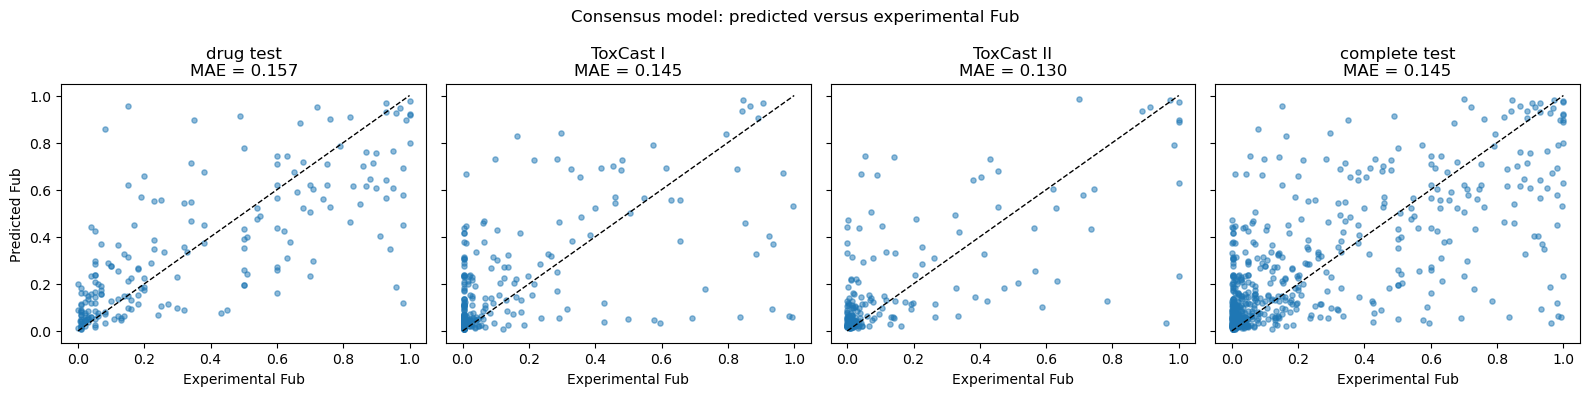

In [27]:
# Visual comparison: actual versus consensus predictions for each independent test set.
fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4),
    sharex=True,
    sharey=True,
)

plot_order = ["drug test", "ToxCast I", "ToxCast II", "complete test"]

for axis, dataset_name in zip(axes, plot_order):
    result = pred[dataset_name]

    axis.scatter(
        result["actual"],
        result["consensus"],
        s=14,
        alpha=0.5,
    )
    axis.plot([0, 1], [0, 1], "k--", linewidth=1)

    mae_value = mean_absolute_error(
        result["actual"],
        result["consensus"],
    )

    axis.set_title(f"{dataset_name}\nMAE = {mae_value:.3f}")
    axis.set_xlabel("Experimental Fub")

axes[0].set_ylabel("Predicted Fub")
plt.suptitle("Consensus model: predicted versus experimental Fub")
plt.tight_layout()
plt.show()


## 13. Error analysis by binding strength

The paper reports that model errors are inversely related to experimental Fub:
- Highly bound: Fub < 0.15;
- Moderately bound: 0.15 ≤ Fub ≤ 0.85;
- Weakly bound: Fub > 0.85.

The models perform best for highly bound compounds and worst for weakly bound compounds. This breakdown is important because a good overall MAE can conceal poor predictions in the weakly bound region.

In [28]:
complete_test = pred["complete test"].copy()

binding_groups = [
    ("Highly bound (<0.15)", complete_test["actual"] < 0.15),
    (
        "Moderately bound (0.15–0.85)",
        (complete_test["actual"] >= 0.15)
        & (complete_test["actual"] <= 0.85),
    ),
    ("Weakly bound (>0.85)", complete_test["actual"] > 0.85),
]

binding_rows = []

for label, mask in binding_groups:
    if mask.sum() == 0:
        continue

    row = {
        "binding_group": label,
        "n": int(mask.sum()),
    }

    for model_name in MODEL_NAMES:
        row[model_name] = mean_absolute_error(
            complete_test.loc[mask, "actual"],
            complete_test.loc[mask, model_name],
        )

    binding_rows.append(row)

by_binding = pd.DataFrame(binding_rows).set_index("binding_group")
display(by_binding.round(3))


,n,kNN,SVM,RF,consensus
binding_group,,,,,
Highly bound (<0.15),375,0.111,0.123,0.073,0.099
Moderately bound (0.15–0.85),181,0.208,0.233,0.208,0.194
Weakly bound (>0.85),50,0.323,0.319,0.311,0.313


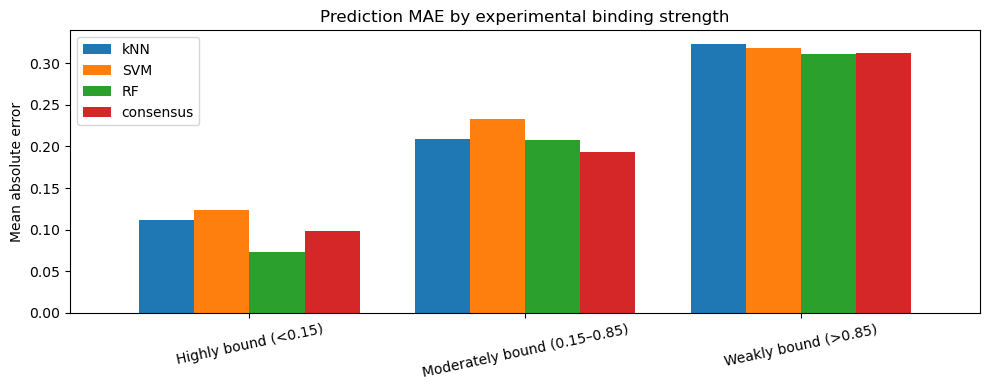

In [29]:
ax = by_binding[MODEL_NAMES].plot(
    kind="bar",
    figsize=(10, 4),
    width=0.8,
)

ax.set_title("Prediction MAE by experimental binding strength")
ax.set_ylabel("Mean absolute error")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.show()


## 14. Error analysis by ionization class (only if available)

The paper assigns ionization classes using predicted ionization microstates at physiological pH (7.4):
- acids;
- bases;
- neutrals;
- zwitterions.

The paper reports the consensus model performs best for neutrals, then acids, then bases, and least reliably for zwitterions. It discusses albumin (HSA) and AAG binding as a possible mechanistic explanation.

**Data limitation:** the column names you supplied earlier do not include an ionization-class column. This cell searches for common ionization-column names. If none exists, it prints a clear message and skips this analysis. It does not infer ionization class from `a_base`, `a_nN`, or `a_nS`.

In [30]:
possible_ionization_columns = [
    "Ionization",
    "Ionization class",
    "Ionization_Class",
    "ionization",
    "ionization_class",
]

ionization_column = next(
    (column for column in possible_ionization_columns if column in data.columns),
    None,
)

if ionization_column is None:
    print(
        "Ionization analysis skipped: no explicit ionization-class column "
        "was found in the supplied spreadsheet."
    )
    by_ionization = None
else:
    ion_data = data.loc[
        data.index.intersection(complete_test.index),
        [ionization_column],
    ].copy()

    ion_results = complete_test.join(ion_data, how="left")
    ion_results[ionization_column] = (
        ion_results[ionization_column]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    ion_rows = []

    for ion_class in ["neutral", "acid", "base", "zwitterion"]:
        mask = ion_results[ionization_column] == ion_class

        if mask.sum() == 0:
            continue

        row = {
            "ionization": ion_class,
            "n": int(mask.sum()),
        }

        for model_name in MODEL_NAMES:
            row[model_name] = mean_absolute_error(
                ion_results.loc[mask, "actual"],
                ion_results.loc[mask, model_name],
            )

        ion_rows.append(row)

    if ion_rows:
        by_ionization = pd.DataFrame(ion_rows).set_index("ionization")
        display(by_ionization.round(3))
    else:
        by_ionization = None
        print("Ionization column found, but no recognised class labels were present.")


Ionization analysis skipped: no explicit ionization-class column was found in the supplied spreadsheet.


## 15. Applicability domain

The paper considers whether a test compound lies within the chemical space represented by the pharmaceutical training data.

This notebook implements two simple checks:

1. **Descriptor bounding box:** flag a test compound if any descriptor is below the training minimum or above the training maximum.
2. **PCA range check:** standardise descriptors using training-set statistics, fit PCA on the training data, and flag a test compound if any principal-component score falls outside the training score range.

These are screening diagnostics, not guarantees of prediction reliability. The paper found that neither approach consistently identified the worst predictions.

In [31]:
# Fit imputation and scaling on the pharmaceutical training set only.
ad_imputer = SimpleImputer(strategy="median")
X_train_ad = ad_imputer.fit_transform(train_df[descriptor_columns])

all_test_df = pd.concat(
    [drug_test, tox1, tox2],
    axis=0,
).sort_index()

X_test_ad = ad_imputer.transform(all_test_df[descriptor_columns])

# Bounding-box applicability domain.
train_min = pd.Series(
    X_train_ad.min(axis=0),
    index=descriptor_columns,
)
train_max = pd.Series(
    X_train_ad.max(axis=0),
    index=descriptor_columns,
)

test_ad_frame = pd.DataFrame(
    X_test_ad,
    index=all_test_df.index,
    columns=descriptor_columns,
)

outside_box = (
    (test_ad_frame < train_min)
    | (test_ad_frame > train_max)
).any(axis=1)

# PCA applicability domain.
ad_scaler = StandardScaler()
X_train_scaled = ad_scaler.fit_transform(X_train_ad)
X_test_scaled = ad_scaler.transform(X_test_ad)

pca = PCA()
train_pc_scores = pca.fit_transform(X_train_scaled)
test_pc_scores = pca.transform(X_test_scaled)

pc_min = train_pc_scores.min(axis=0)
pc_max = train_pc_scores.max(axis=0)

outside_pca = (
    (test_pc_scores < pc_min)
    | (test_pc_scores > pc_max)
).any(axis=1)

print(
    f"Bounding box: {outside_box.sum()} of {len(outside_box)} test compounds "
    f"outside ({outside_box.mean() * 100:.1f}%)"
)
print(
    f"PCA ranges:   {outside_pca.sum()} of {len(outside_pca)} test compounds "
    f"outside ({outside_pca.mean() * 100:.1f}%)"
)


Bounding box: 46 of 606 test compounds outside (7.6%)
PCA ranges:   60 of 606 test compounds outside (9.9%)


In [32]:
# Compare consensus errors for flagged and unflagged compounds.
ad_results = pred["complete test"].reindex(all_test_df.index).copy()
ad_results["absolute_error"] = (
    ad_results["actual"] - ad_results["consensus"]
).abs()
ad_results["outside_bounding_box"] = outside_box
ad_results["outside_pca"] = outside_pca

ad_summary = pd.DataFrame({
    "Bounding box": [
        ad_results.loc[outside_box, "absolute_error"].mean(),
        ad_results.loc[~outside_box, "absolute_error"].mean(),
        int(outside_box.sum()),
    ],
    "PCA": [
        ad_results.loc[outside_pca, "absolute_error"].mean(),
        ad_results.loc[~outside_pca, "absolute_error"].mean(),
        int(outside_pca.sum()),
    ],
}, index=["MAE outside", "MAE inside", "Number outside"])

display(ad_summary.round(3))

extreme_error = ad_results["absolute_error"] > 0.7

print("Consensus predictions with absolute error > 0.7:", int(extreme_error.sum()))
print(
    "Extreme-error compounds flagged by bounding box:",
    int((extreme_error & outside_box).sum()),
)
print(
    "Extreme-error compounds flagged by PCA:",
    int((extreme_error & outside_pca).sum()),
)


,Bounding box,PCA
MAE outside,0.108,0.137
MAE inside,0.148,0.146
Number outside,46.000,60.000


Consensus predictions with absolute error > 0.7: 10
Extreme-error compounds flagged by bounding box: 1
Extreme-error compounds flagged by PCA: 2


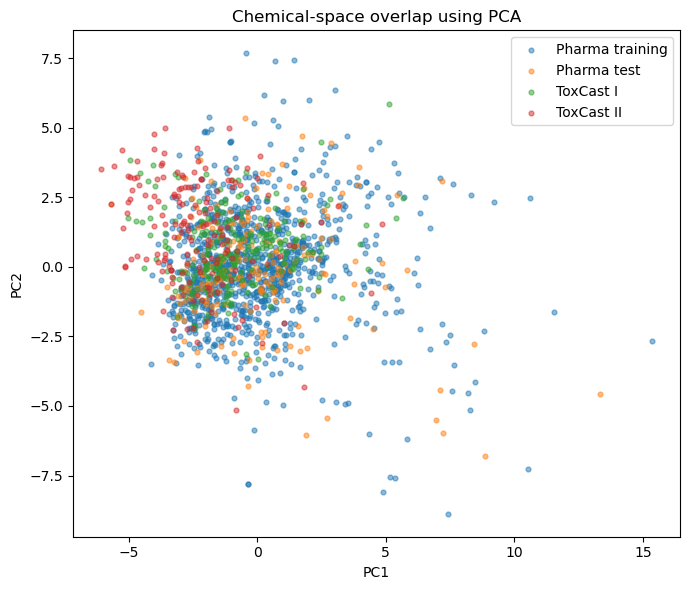

Variance explained by first two PCs: 0.448


In [33]:
# Plot the first two principal components to inspect chemical-space overlap.
plt.figure(figsize=(7, 6))

plot_frames = [
    (train_df, "Pharma training"),
    (drug_test, "Pharma test"),
    (tox1, "ToxCast I"),
    (tox2, "ToxCast II"),
]

for frame, label in plot_frames:
    X_frame = ad_imputer.transform(frame[descriptor_columns])
    X_frame_scaled = ad_scaler.transform(X_frame)
    scores = pca.transform(X_frame_scaled)

    plt.scatter(
        scores[:, 0],
        scores[:, 1],
        s=12,
        alpha=0.5,
        label=label,
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Chemical-space overlap using PCA")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Variance explained by first two PCs:",
    round(pca.explained_variance_ratio_[:2].sum(), 3),
)


## 18. Final interpretation and report checklist

Use your own computed results from the tables above. Do not copy the paper's reference numbers as if they were your model's results.

### What the paper found

- The consensus model had the best overall balance in the paper: complete-test MAE 0.133, RMSE 0.206, and R² 0.56.
- The RF model was the strongest individual model on the complete test set (MAE 0.131).
- Prediction errors were much lower for highly bound compounds than for weakly bound compounds.
- Neutral and acidic compounds were predicted more reliably than bases and zwitterions.
- The authors suggested that the ionization-dependent pattern may reflect stronger representation of albumin-related binding than AAG-related binding in the descriptors.
- Applicability-domain checks did not reliably identify all compounds with very large prediction errors.
- The paper cautions that experimental Fub measurements themselves can be variable, placing a limit on achievable model accuracy.

### Important limitations of this notebook

1. The supplied column list contains no explicit ionization-class field. The ionization analysis is skipped unless such a column is present in the workbook.
2. The feature-selection procedure is a reproducible approximation of the paper's repeated Random Forest ranking. It does not reconstruct every BIC curve or the authors' exact model-specific descriptor subsets.
3. Your spreadsheet's `Dte` partition is used directly, so the pharmaceutical test set matches the paper's intended 200-compound partition if the supplied file is the paper's curated file.
4. Small differences from Table 1 are expected if the original random seeds, exact descriptor subsets, preprocessing details, or software versions differ.
5. The optional Gradient Boosting experiment is an extension, not part of the paper's original comparison.

### Suggested conclusion structure for your project report

- State whether pharmaceutical-only training transferred successfully to ToxCast I and ToxCast II.
- Identify the best individual model and whether consensus improved RMSE.
- Discuss the binding-strength groups, especially weakly bound compounds.
- Include the ionization-class analysis only if the real ionization labels are available.
- Explain what the applicability-domain checks did and did not identify.
- Discuss experimental measurement uncertainty as a limit on prediction performance.